In [9]:
import pandas as pd
import matplotlib.pyplot as plt

# Load data
train_df = pd.read_csv('data/1-VLSP2018-SA-Restaurant-train.csv')
print("Shape:", train_df.shape)
print("\nColumns:\n", train_df.columns.tolist())
print("\nFirst rows:")
train_df.head()

Shape: (2961, 13)

Columns:
 ['Review', 'AMBIENCE#GENERAL', 'DRINKS#PRICES', 'DRINKS#QUALITY', 'DRINKS#STYLE&OPTIONS', 'FOOD#PRICES', 'FOOD#QUALITY', 'FOOD#STYLE&OPTIONS', 'LOCATION#GENERAL', 'RESTAURANT#GENERAL', 'RESTAURANT#MISCELLANEOUS', 'RESTAURANT#PRICES', 'SERVICE#GENERAL']

First rows:


,Review,AMBIENCE#GENERAL,DRINKS#PRICES,DRINKS#QUALITY,DRINKS#STYLE&OPTIONS,FOOD#PRICES,FOOD#QUALITY,FOOD#STYLE&OPTIONS,LOCATION#GENERAL,RESTAURANT#GENERAL,RESTAURANT#MISCELLANEOUS,RESTAURANT#PRICES,SERVICE#GENERAL
0,"_ Ảnh chụp từ hôm qua, đi chơi với gia đình và...",0,0,0,0,0,3,3,0,0,0,0,0
1,"_Hương vị thơm ngon, ăn cay cay rất thích, nêm...",1,0,0,0,3,1,1,0,1,0,3,2
2,- 1 bàn tiệc hoành tráng 3 đứa ăn no muốn tắt ...,2,0,0,0,1,1,1,2,1,1,0,1
3,- Các bạn nhìn cái chảo này có to không 🙄🙄🙄- T...,0,0,0,0,0,1,1,0,1,0,0,0
4,"- Cháo: có nhiều hương cho các bạn chọn, nhưng...",0,0,0,0,0,1,1,0,0,0,0,0


In [10]:
# Xác định cột review và các cột aspect-sentiment
review_col = train_df.columns[0]  # Cột đầu tiên thường là review
aspect_cols = [c for c in train_df.columns if c != review_col]

print(f"Review column: {review_col}")
print(f"Aspect columns ({len(aspect_cols)}): {aspect_cols}")
print(f"\nMissing values:\n{train_df.isnull().sum()}")
print(f"\nText length stats:\n{train_df[review_col].str.len().describe()}")

# Phân phối nhãn cho từng aspect
for col in aspect_cols:
    print(f"\n--- {col} ---")
    print(train_df[col].value_counts())

Review column: Review
Aspect columns (12): ['AMBIENCE#GENERAL', 'DRINKS#PRICES', 'DRINKS#QUALITY', 'DRINKS#STYLE&OPTIONS', 'FOOD#PRICES', 'FOOD#QUALITY', 'FOOD#STYLE&OPTIONS', 'LOCATION#GENERAL', 'RESTAURANT#GENERAL', 'RESTAURANT#MISCELLANEOUS', 'RESTAURANT#PRICES', 'SERVICE#GENERAL']

Missing values:
Review                      0
AMBIENCE#GENERAL            0
DRINKS#PRICES               0
DRINKS#QUALITY              0
DRINKS#STYLE&OPTIONS        0
FOOD#PRICES                 0
FOOD#QUALITY                0
FOOD#STYLE&OPTIONS          0
LOCATION#GENERAL            0
RESTAURANT#GENERAL          0
RESTAURANT#MISCELLANEOUS    0
RESTAURANT#PRICES           0
SERVICE#GENERAL             0
dtype: int64

Text length stats:
count    2961.000000
mean      245.199595
std       207.781136
min         4.000000
25%        99.000000
50%       215.000000
75%       327.000000
max      2890.000000
Name: Review, dtype: float64

--- AMBIENCE#GENERAL ---
AMBIENCE#GENERAL
0    2224
1     513
3     132
2   

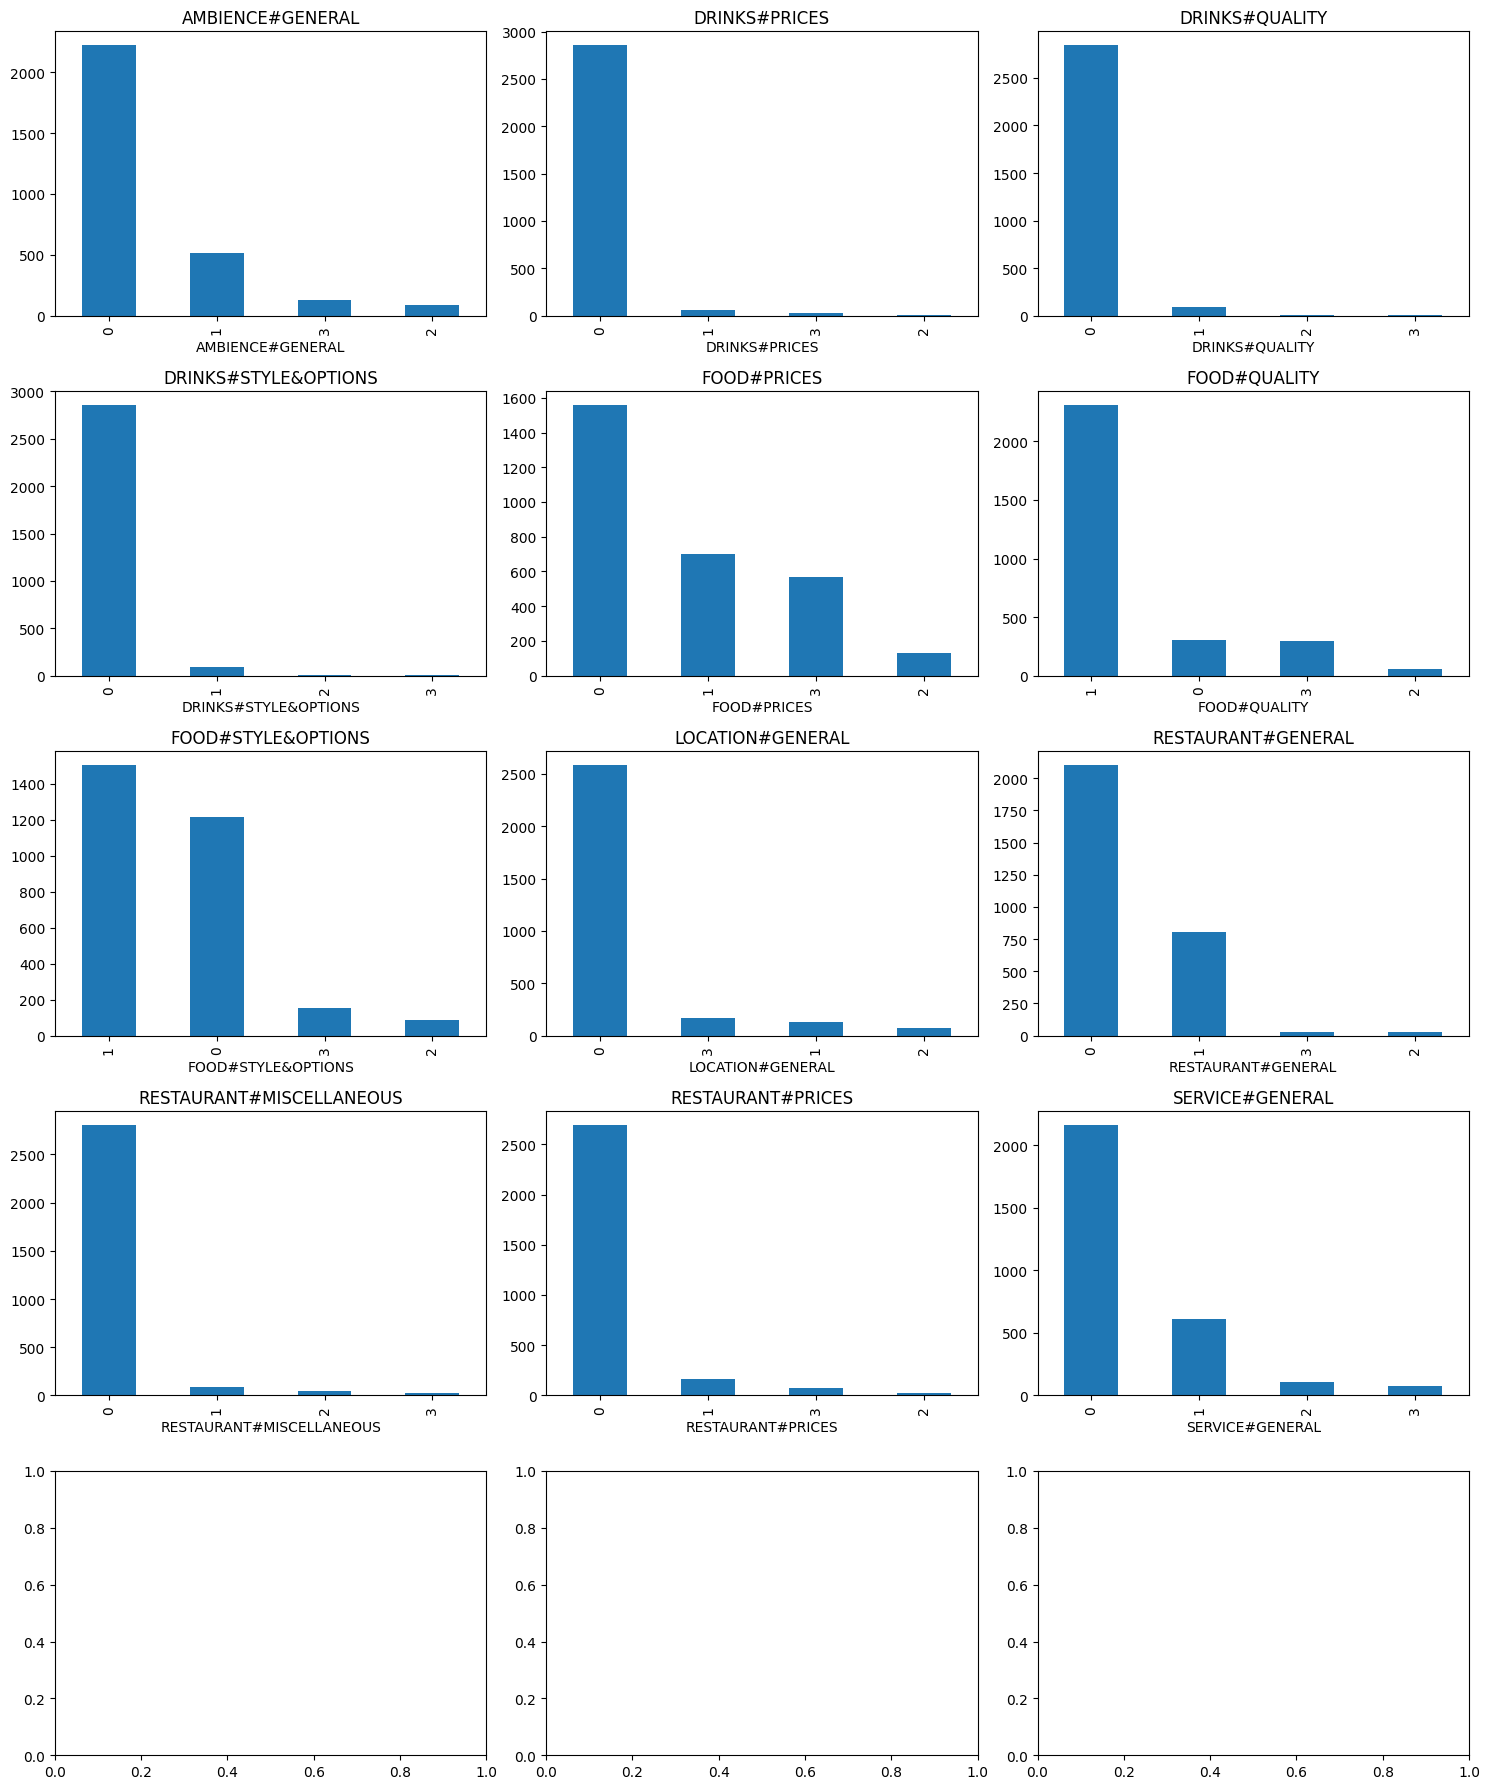

In [11]:
# Visualize label distribution
fig, axes = plt.subplots(len(aspect_cols) // 3 + 1, 3, figsize=(15, len(aspect_cols) * 1.5))
axes = axes.flatten()
for i, col in enumerate(aspect_cols):
    train_df[col].value_counts().plot(kind='bar', ax=axes[i], title=col)
plt.tight_layout()
plt.show()

# Kế hoạch Training Phân Tích Cảm Xúc

## 1. Preprocessing
- Chuẩn hóa text tiếng Việt (lowercase, bỏ ký tự đặc biệt)
- Tokenization với `pyvi` hoặc `underthesern`
- Loại bỏ stopwords tiếng Việt

## 2. Feature Engineering
- **Cách 1**: TF-IDF → classifiers truyền thống (SVM, LogisticRegression)
- **Cách 2**: PhoBERT embeddings → fine-tune transformer

## 3. Modeling (Aspect-Based Sentiment)
- Mỗi aspect column là 1 bài toán phân loại riêng (positive/negative/neutral)
- **Option A**: Train N classifiers riêng biệt (1 per aspect)
- **Option B**: Multi-task learning với shared encoder (PhoBERT)

## 4. Evaluation
- Macro F1-score (vì dữ liệu imbalanced)
- Confusion matrix per aspect

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score, confusion_matrix
import warnings
import numpy as np
warnings.filterwarnings('ignore')

vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1, 2))

# Lưu kết quả để phân tích
results = {}

# Train 1 model per aspect
for col in aspect_cols:
    subset = train_df[[review_col, col]].dropna()
    if len(subset) < 10:
        continue
    
    X = subset[review_col]
    y = subset[col]
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y if y.nunique() > 1 else None)
    
    X_train_vec = vectorizer.fit_transform(X_train)
    X_test_vec = vectorizer.transform(X_test)
    
    clf = LogisticRegression(max_iter=1000, class_weight='balanced')
    clf.fit(X_train_vec, y_train)
    
    y_pred = clf.predict(X_test_vec)
    
    results[col] = {
        'y_test': y_test, 'y_pred': y_pred,
        'f1_macro': f1_score(y_test, y_pred, average='macro'),
        'labels': sorted(y.unique()),
        'n_samples': len(subset)
    }
    
    print(f"\n{'='*50}\n{col}\n{'='*50}")
    print(classification_report(y_test, y_pred))

In [ ]:
# !pip install seaborn

'pip' is not recognized as an internal or external command,
operable program or batch file.


In [ ]:
# === PHÂN TÍCH TỔNG HỢP KẾT QUẢ ===
import seaborn as sns

if 'results' not in dir() or len(results) == 0:
    raise RuntimeError("Hãy chạy cell Train (cell 5) trước khi chạy cell này!")

# 1. So sánh F1-macro giữa các aspects
f1_df = pd.DataFrame({
    'Aspect': list(results.keys()),
    'F1-Macro': [r['f1_macro'] for r in results.values()],
    'N_Samples': [r['n_samples'] for r in results.values()]
}).sort_values('F1-Macro', ascending=True)

fig, ax = plt.subplots(figsize=(10, max(4, len(f1_df) * 0.4)))
bars = ax.barh(f1_df['Aspect'], f1_df['F1-Macro'], color='steelblue')
ax.set_xlabel('F1-Macro Score')
ax.set_title('So sánh F1-Macro giữa các Aspects')
ax.set_xlim(0, 1)
for bar, val in zip(bars, f1_df['F1-Macro']):
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2, f'{val:.3f}', va='center')
plt.tight_layout()
plt.show()

print(f"\nF1-Macro trung bình: {f1_df['F1-Macro'].mean():.3f}")
print(f"Aspect tốt nhất: {f1_df.iloc[-1]['Aspect']} ({f1_df.iloc[-1]['F1-Macro']:.3f})")
print(f"Aspect kém nhất: {f1_df.iloc[0]['Aspect']} ({f1_df.iloc[0]['F1-Macro']:.3f})")

RuntimeError: Hãy chạy cell Train (cell 5) trước khi chạy cell này!

In [ ]:
# 2. Confusion Matrix cho top 4 aspects (nhiều sample nhất)
top_aspects = sorted(results.keys(), key=lambda x: results[x]['n_samples'], reverse=True)[:4]

fig, axes = plt.subplots(1, len(top_aspects), figsize=(5 * len(top_aspects), 4))
if len(top_aspects) == 1:
    axes = [axes]

for ax, col in zip(axes, top_aspects):
    r = results[col]
    cm = confusion_matrix(r['y_test'], r['y_pred'], labels=r['labels'])
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=r['labels'], yticklabels=r['labels'], cmap='Blues', ax=ax)
    ax.set_title(f"{col}\n(F1={r['f1_macro']:.3f})")
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')

plt.tight_layout()
plt.show()

# Phân Tích Kết Quả

## Nhận xét:
- **Aspects có F1 cao**: Dữ liệu đủ lớn, labels phân bố tương đối cân bằng
- **Aspects có F1 thấp**: Có thể do imbalanced data hoặc thiếu features đặc trưng
- **TF-IDF + LogisticRegression** là baseline, có thể cải thiện bằng:
  - Thêm preprocessing tiếng Việt (word segmentation)
  - Dùng PhoBERT fine-tuning
  - Data augmentation cho classes thiểu số
  - Thử SVM, Random Forest, hoặc ensemble methods